# Exploratory Data Analysis (EDA)

- To evaluate the proposed Spiking Neural Network (SNN) framework and its initialization strategies, It should be validated it across a diverse set of temporal benchmarks. The following three datasets from the UCR Time Series Classification Archive were chosen because they represent a broad range of signal characteristics:
*   **Varying Application Domains:** They span medical (ECG), industrial manufacturing (Wafer), and acoustic/environmental sensor tracking (InsectSound).
*   **Varying Sequence Lengths:** They range from short, rapid sequences (140 time steps) to much longer temporal dependencies (600 time steps).
*   **Varying Class Distributions:** They provide a mix of perfectly balanced multi-class problems, moderate binary imbalances, and severe multi-class imbalances.
- Testing the network against these contrasting conditions ensures that our hardware-aware initialization and truncated learning methods generalize well to different real-world edge computing scenarios.

---

### 1. InsectSound (Acoustic / Sensor Data)
*   **Domain:** Computational Entomology / Environmental Monitoring.
*   **Description:** This dataset comprises amplitude-modulated intervals produced by flying insects passing through an infrared beam. The original data consists of 10ms segments sampled at 6,000Hz, capturing the distinct wingbeat frequencies of different species and sexes of flies and mosquitoes.
*   **Characteristics:** This is the largest and longest dataset in our suite. It is a perfectly balanced 10-class problem (5,000 instances per class, representing species like *Aedes*, *Culex*, and *Fruit flies*), making it an excellent benchmark for the network's ability to extract complex, high-frequency temporal features over longer integration windows.
*   **Metadata:**
    *   **Instances:** 50,000
    *   **Time Series Length:** 600
    *   **Classes:** 10 (Balanced)
*   *Original Source:* Chen Y. et al., "Flying insect classification with inexpensive sensors," Journal of Insect Behavior (2014). [UCR Archive Link](https://www.timeseriesclassification.com/description.php?Dataset=InsectSound)

### 2. Wafer (Industrial / Manufacturing Data)
*   **Domain:** Semiconductor Fabrication / Inline Process Control.
*   **Description:** This dataset contains measurements recorded by various inline sensors during the fabrication of silicon wafers for microelectronics. Each sequence represents the sensor readings from a single tool processing a single wafer.
*   **Characteristics:** This represents a classic industrial anomaly detection problem. It is a binary classification task distinguishing between "normal" and "abnormal" manufacturing behavior. Unlike InsectSound, Wafer introduces a realistic class imbalance, with abnormal readings comprising only about 10-12% of the data.
*   **Metadata:**
    *   **Instances:** 7,164 (1,000 Train / 6,164 Test)
    *   **Time Series Length:** 152
    *   **Classes:** 2 (Imbalanced)
*   *Original Source:* R. Olszewski, "Generalized feature extraction for structural pattern recognition in time-series data," Carnegie Mellon University (2001). [UCR Archive Link](https://www.timeseriesclassification.com/description.php?Dataset=Wafer)

### 3. ECG5000 (Medical / Physiological Data)
*   **Domain:** Healthcare / Cardiology.
*   **Description:** Extracted from a 20-hour electrocardiogram (ECG) recording of a patient with severe congestive heart failure (from the Physionet BIDMC database). The data was pre-processed to extract individual heartbeats and interpolate them to an equal length.
*   **Characteristics:** This dataset tests the network's ability to handle severe class imbalances in physiological data. While it is a 5-class problem (representing normal beats and various arrhythmias), the vast majority of instances belong to a single "normal" class, making it a highly challenging anomaly detection benchmark.
*   **Metadata:**
    *   **Instances:** 5,000
    *   **Time Series Length:** 140
    *   **Classes:** 5 (Severely Imbalanced)
*   *Original Source:* Goldberger AL. et al., "PhysioBank, PhysioToolkit, and PhysioNet: Components of a New Research Resource for Complex Physiologic Signals," Circulation (2000). [UCR Archive Link](https://www.timeseriesclassification.com/description.php?Dataset=ECG5000)

In [1]:
import warnings
warnings.filterwarnings('ignore')

from edgesnn.data_utils import load_ucr_data, make_datasets
from edgesnn.plotting import plot_class_distribution, plot_mean_std_series

In [2]:
DATASET_DIR = "../Data"
datasets = ["ECG5000", "Wafer", "InsectSound"]
FIG_DIR = "../reports/figures"

### Dataset class visualization

--- Analyzing ECG5000 ---
[plot] saved ../reports/figures/ECG5000_class_dist_raw.png


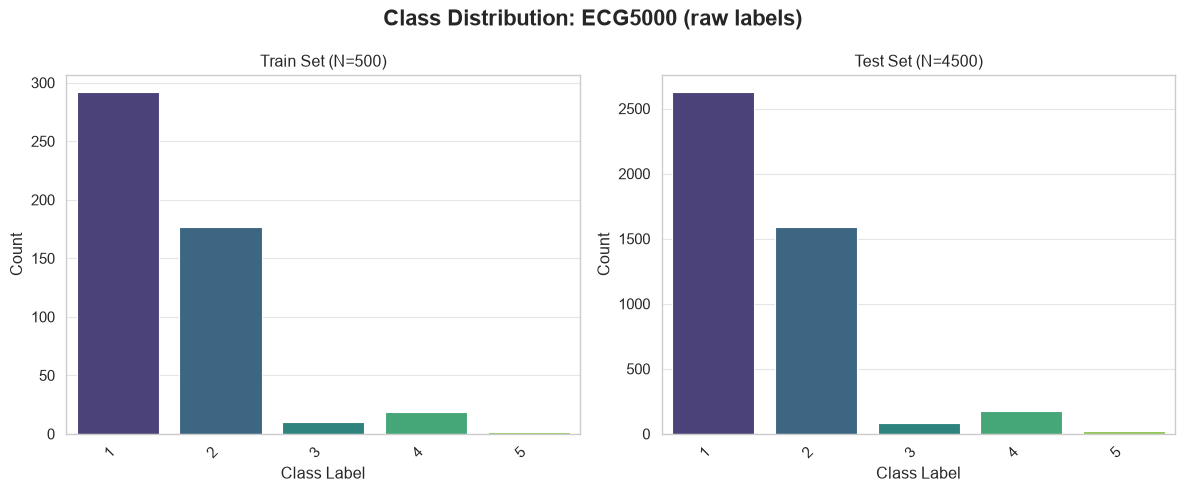

[plot] saved ../reports/figures/ECG5000_mean_std_raw.png


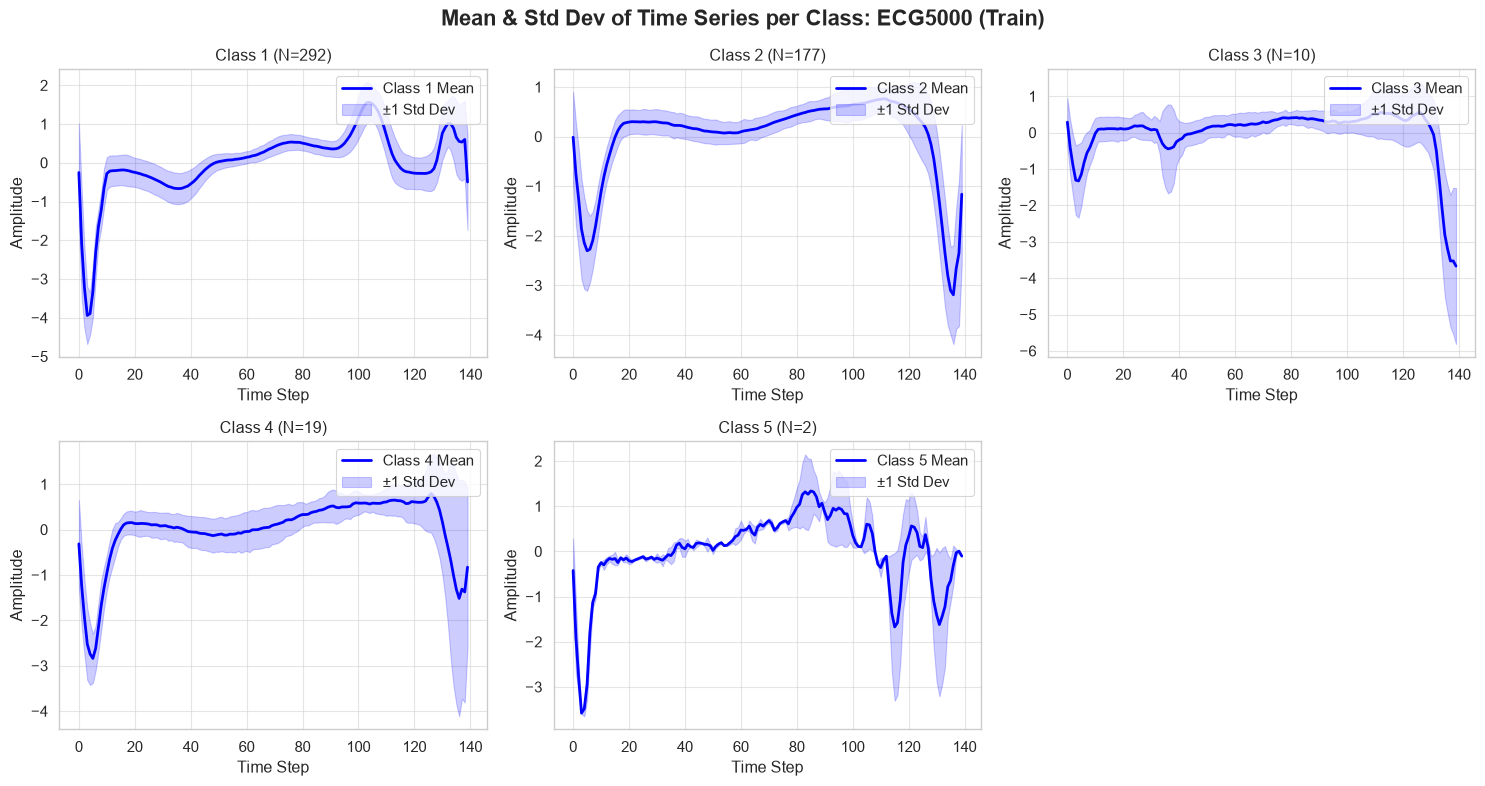



--- Analyzing Wafer ---
[plot] saved ../reports/figures/Wafer_class_dist_raw.png


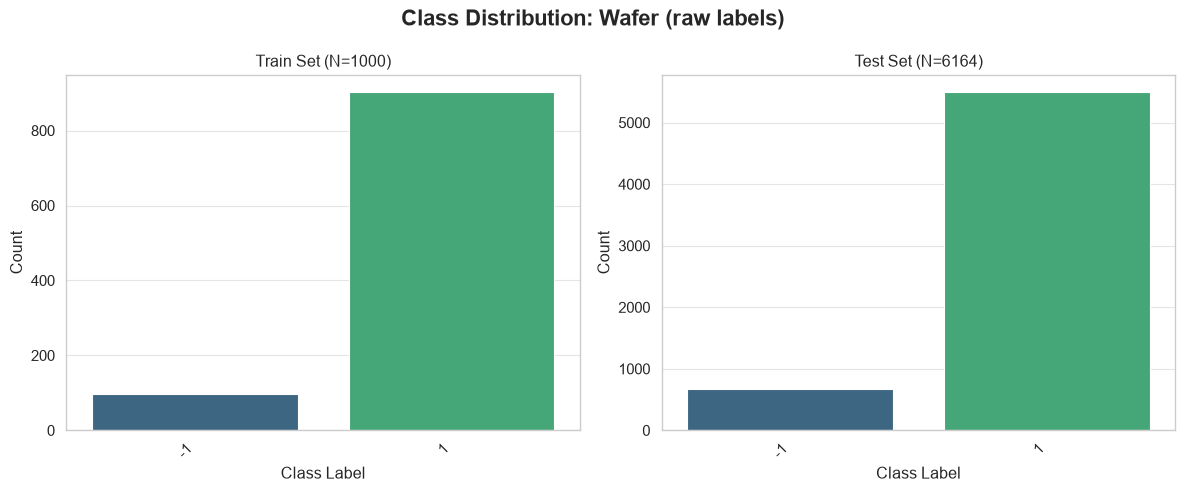

[plot] saved ../reports/figures/Wafer_mean_std_raw.png


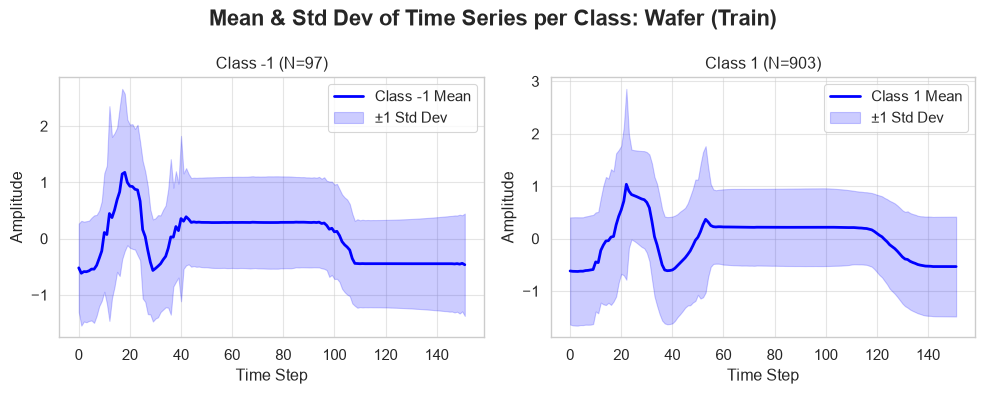



--- Analyzing InsectSound ---
[plot] saved ../reports/figures/InsectSound_class_dist_raw.png


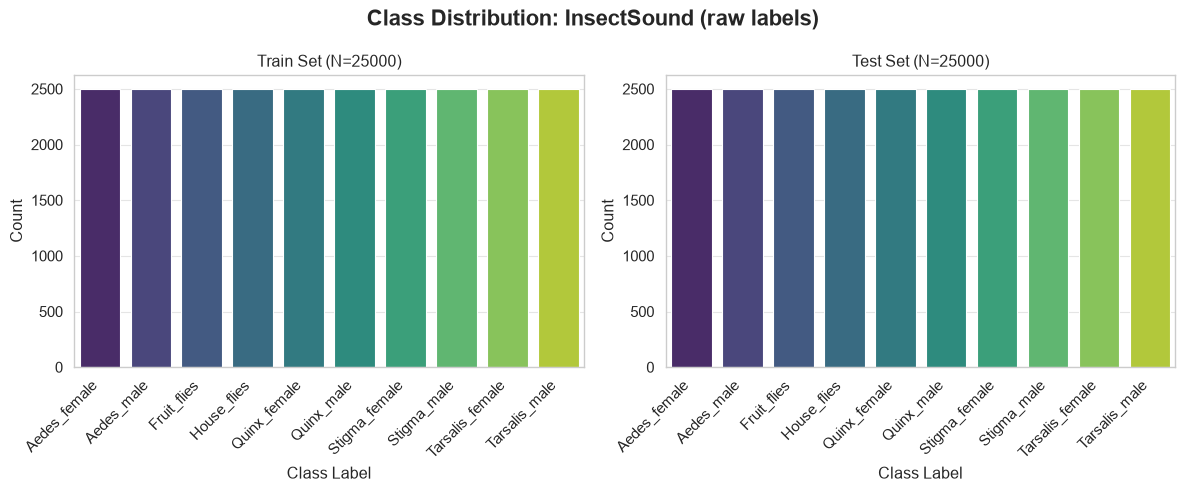

[plot] saved ../reports/figures/InsectSound_mean_std_raw.png


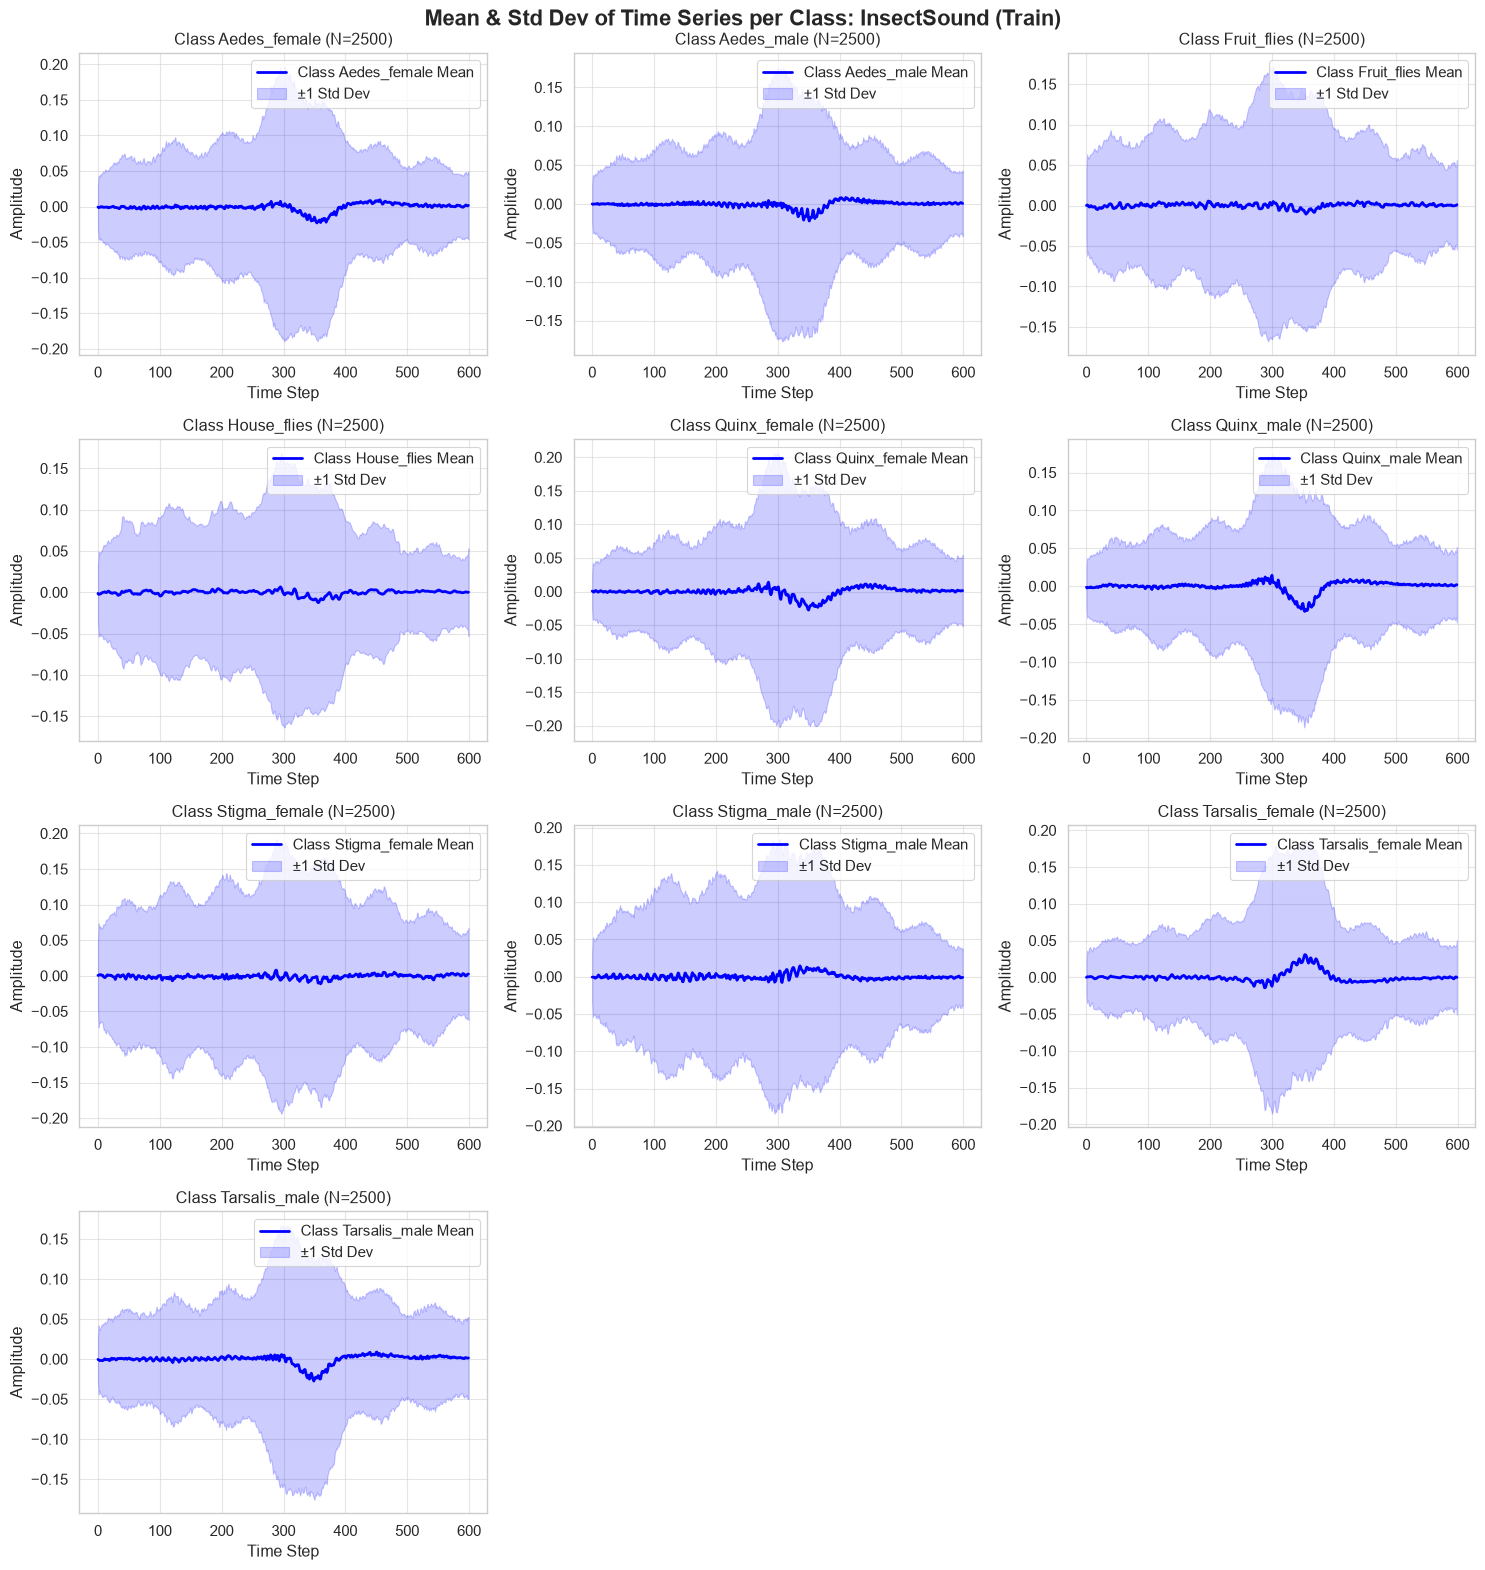

In [3]:
for dataset in datasets:
    print(f"--- Analyzing {dataset} ---")

    df_train, df_test = load_ucr_data(DATASET_DIR, dataset)
    if df_train is None:
        continue

    plot_class_distribution(df_train, df_test, f"{dataset} (raw labels)", sharey=False,
                              save_path=f"{FIG_DIR}/{dataset}_class_dist_raw.png")

    # Train set only — inspecting the test set would leak into design decisions.
    plot_mean_std_series(df_train, dataset, split_name="Train",
                           save_path=f"{FIG_DIR}/{dataset}_mean_std_raw.png")
    print("\n")

### Visualizing after class aggregation

--- ECG5000: T=140, C=2 ---


,class,name,count,proportion
0,0,normal (1),292,0.584
1,1,abnormal (2-5),208,0.416


[plot] saved ../reports/figures/ECG5000_class_dist_encoded.png


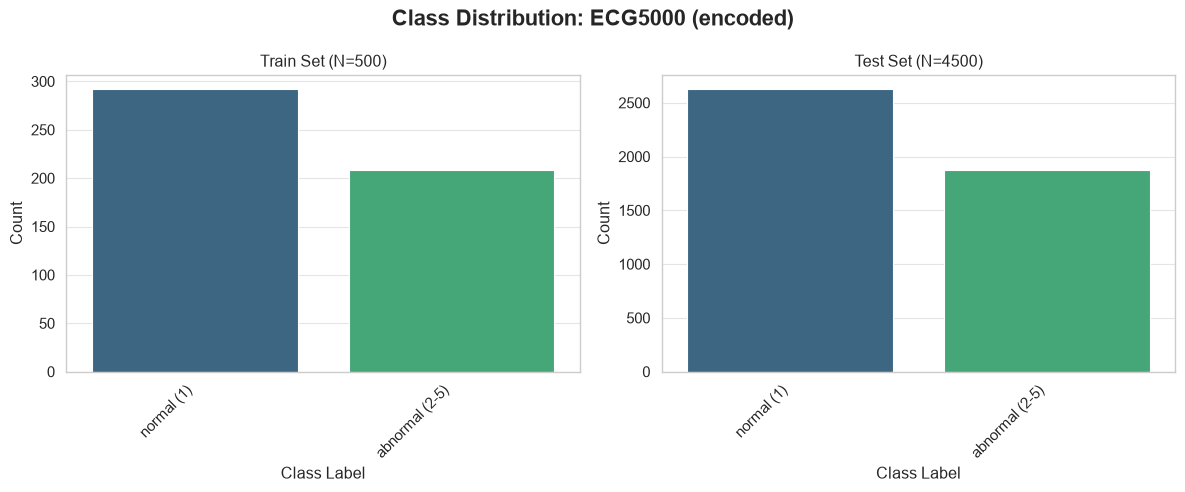

[plot] saved ../reports/figures/ECG5000_mean_std_encoded.png


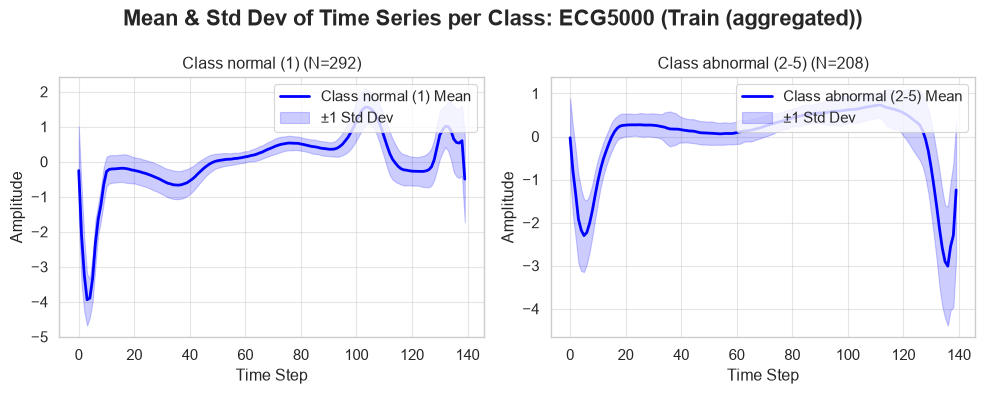



--- Wafer: T=152, C=2 ---


,class,name,count,proportion
0,0,abnormal (-1),97,0.097
1,1,normal (1),903,0.903


[plot] saved ../reports/figures/Wafer_class_dist_encoded.png


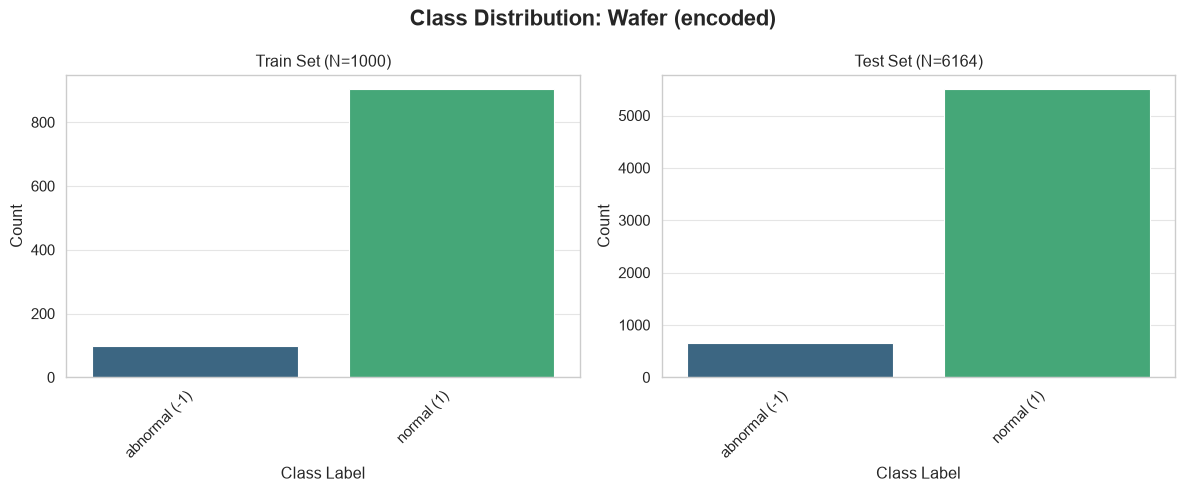

[plot] saved ../reports/figures/Wafer_mean_std_encoded.png


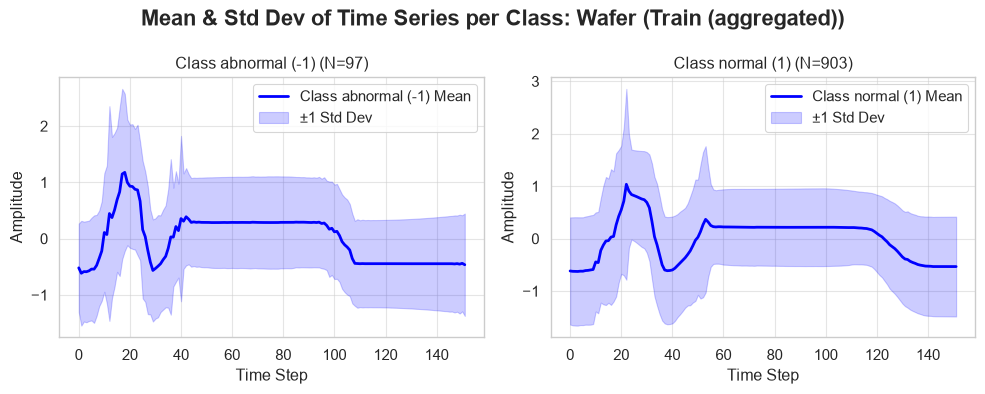



--- InsectSound: T=600, C=10 ---


,class,name,count,proportion
0,0,Aedes_female,2500,0.1
1,1,Aedes_male,2500,0.1
2,2,Fruit_flies,2500,0.1
3,3,House_flies,2500,0.1
4,4,Quinx_female,2500,0.1
5,5,Quinx_male,2500,0.1
6,6,Stigma_female,2500,0.1
7,7,Stigma_male,2500,0.1
8,8,Tarsalis_female,2500,0.1
9,9,Tarsalis_male,2500,0.1


[plot] saved ../reports/figures/InsectSound_class_dist_encoded.png


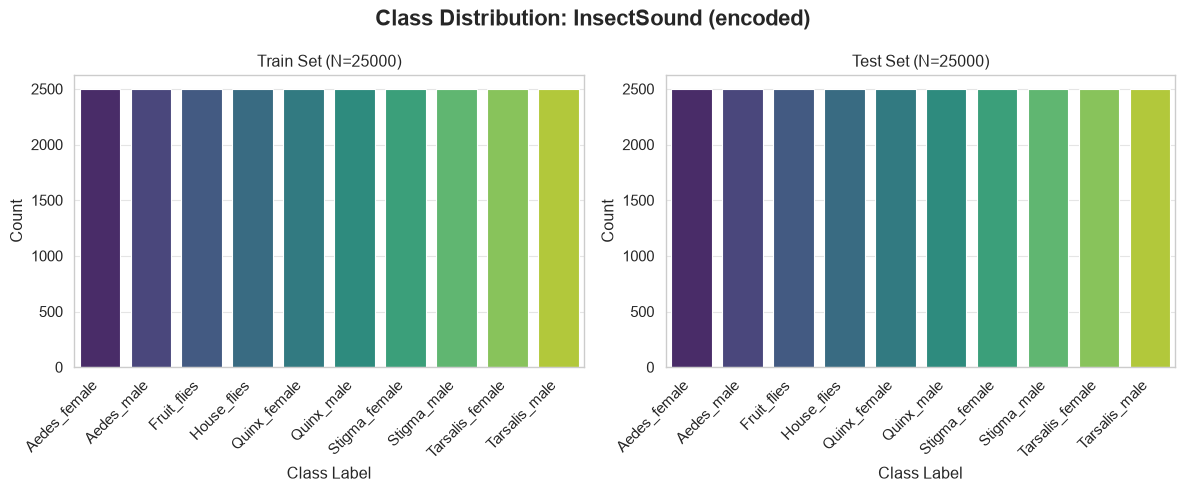

[plot] saved ../reports/figures/InsectSound_mean_std_encoded.png


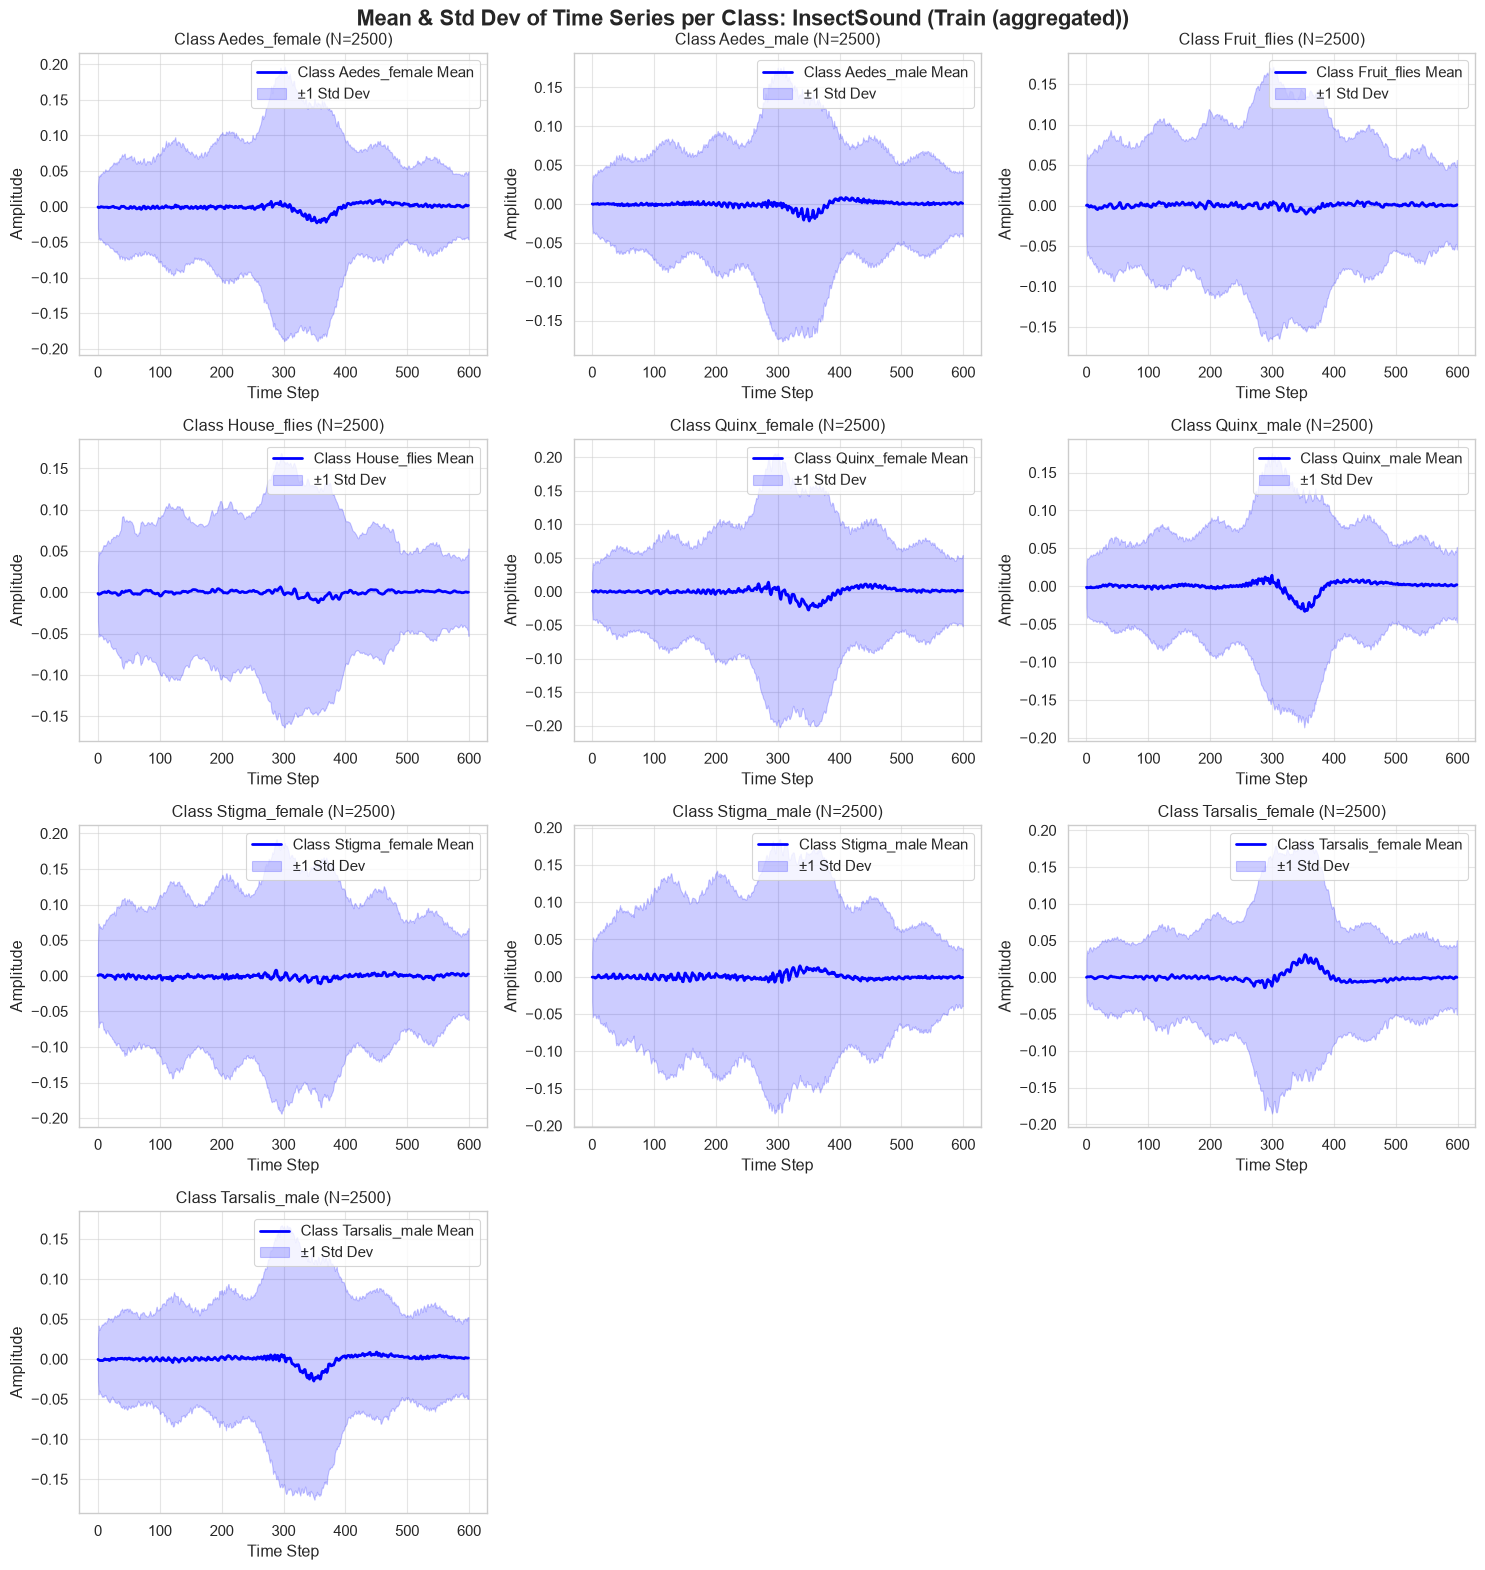

In [4]:
for dataset in datasets:
      train_ds, test_ds = make_datasets(DATASET_DIR, dataset)
      print(f"--- {dataset}: T={train_ds.seq_len}, C={train_ds.num_classes} ---")

      # display counts as a table
      display(train_ds.class_counts())

      plot_class_distribution(train_ds.to_frame(), test_ds.to_frame(),
                              f"{dataset} (encoded)",
                              class_names=train_ds.class_names, sharey=False,
                              save_path=f"{FIG_DIR}/{dataset}_class_dist_encoded.png")

      # denormalize=True: after z-scoring the y-axis is in std devs, which reads
      # oddly for a "what the waveform looks like" figure.
      plot_mean_std_series(train_ds.to_frame(denormalize=True), dataset,
                           split_name="Train (aggregated)",
                           class_names=train_ds.class_names,
                           save_path=f"{FIG_DIR}/{dataset}_mean_std_encoded.png")
      print("\n")